## Items to do:
need to organize code more. Note:
1. where is skip heights
2. inputs from config file

Assess impacts of fit options (affect Chi2)
1. single scaling (fixed activity ratio)
2. variable bins vs fixed bins (chi2)
3. impact of first bin
4. lower stats (profile likelihood)?

attenuation goes opposite way... should add reflector at top of chamber

In [54]:
## Atown's stuff
import os
import sys
import time
sys.path.append("..")
from globalsC2 import *

import sys

import matplotlib.pyplot as plt
import numpy as np
import PickleLite as PL

# import MakeSpectra as MS
print(COMP2PATH)

/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2


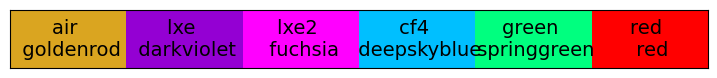

In [55]:
## Style setup — PDEStyle colors + larger fonts
import PDEStyle as PS
ms = PS.MyStyleSet()
ms.SetMPLcolors()   # sets matplotlib prop_cycle to PDEStyle colors

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 11,
})

ms.show()

In [56]:
from datetime import datetime

def days_between(date1, date2, fmt="%Y-%m-%d"):
    """Return the number of days between two dates (date2 - date1)."""
    d1 = datetime.strptime(date1, fmt)
    d2 = datetime.strptime(date2, fmt)
    return np.abs((d2 - d1).days)
  
def ReducedActivity(days, hlife):
    """Calculate the reduced activity of a radioactive isotope after a certain number of days, given its half-life."""
    return 0.5 ** (days / hlife)

In [57]:
actCo = 4713000
actCs = 135500

actRatio = actCo / actCs
print("Activity Ratio Co-60 / Cs-137: ", actRatio)

fOmega = (1 - np.cos(1.5 * np.pi / 180))/2  # fraction of 4pi covered by detector at 1.5 degrees
print("Detector solid angle fraction: ", fOmega)
print(fOmega * actCo)
print(fOmega * actCs)

thetaOpening = np.arctan(2/100)*180/np.pi ## its 4mm opening, 10cm long, so half angle is arctan(2/100) in degrees
print("Detector opening angle (degrees): ", thetaOpening, "deg \n\n")

##########
Ci2Beq = 3.7e10
dataDate = "2022-03-01"

actCs_2 = 11.1e-6 * Ci2Beq
dateCs = "1974-06-01"
hlCs = 30.17 * 365  # in days
daysCs = days_between(dateCs, dataDate)

actCo_2 = 6.2e-3 * Ci2Beq
dateCo = "2018-01-16"
daysCo = days_between(dateCo, dataDate)
hlCo = 271.8
# print("Days since Cs-137 was produced: ", daysCs)
# print("activity reduction",ReducedActivity(daysCs, hlCs))

actCs_calc = actCs_2 * ReducedActivity(daysCs, hlCs)
print("original Cs-137 activity: ", actCs_2)
print("calculated Cs-137 activity: ", actCs_calc)

actCo_calc = actCo_2 * ReducedActivity(daysCo, hlCo)
print("original Co-60 activity: ", actCo_2)
print("calculated Co-60 activity: ", actCo_calc)

## overwrite activities with calculated values
actCs = actCs_calc
actCo = actCo_calc

Activity Ratio Co-60 / Cs-137:  34.78228782287823
Detector solid angle fraction:  0.00017133751222137006
807.513695099317
23.216232905995643
Detector opening angle (degrees):  1.1457628381751035 deg 


original Cs-137 activity:  410700.0
calculated Cs-137 activity:  137017.98697404933
original Co-60 activity:  229400000.0
calculated Co-60 activity:  4940174.165757093


In [58]:
# Example usage (uncomment and set COMP2PATH if not already in scope):
save_dir = os.path.join(COMP2PATH, "DataAnalysis", "saved_spectra2")

## opening multiple in one file
co_bare = PL.load_snap_list(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"))
print(type(co_bare[0]))
print(f"Loaded {len(co_bare)} Co bare LiteRun objects. First IDs:", [lr.id for lr in co_bare[:3]])

# Optional: tiny loader example which also works
# with open(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"), "rb") as f:
#   co_bare_loaded = pickle.load(f)
#   print(f"Loaded {len(co_bare_loaded)} Co bare snapshots. First IDs:", [d["id"] for d in co_bare_loaded[:3]])
#   print(type(co_bare_loaded[0]))

<class 'PickleLite.LiteRun'>
Loaded 5 Co bare LiteRun objects. First IDs: ['202203031411', '202203031118', '202203031135']


---
### Load data spectra

166300
110521
130428


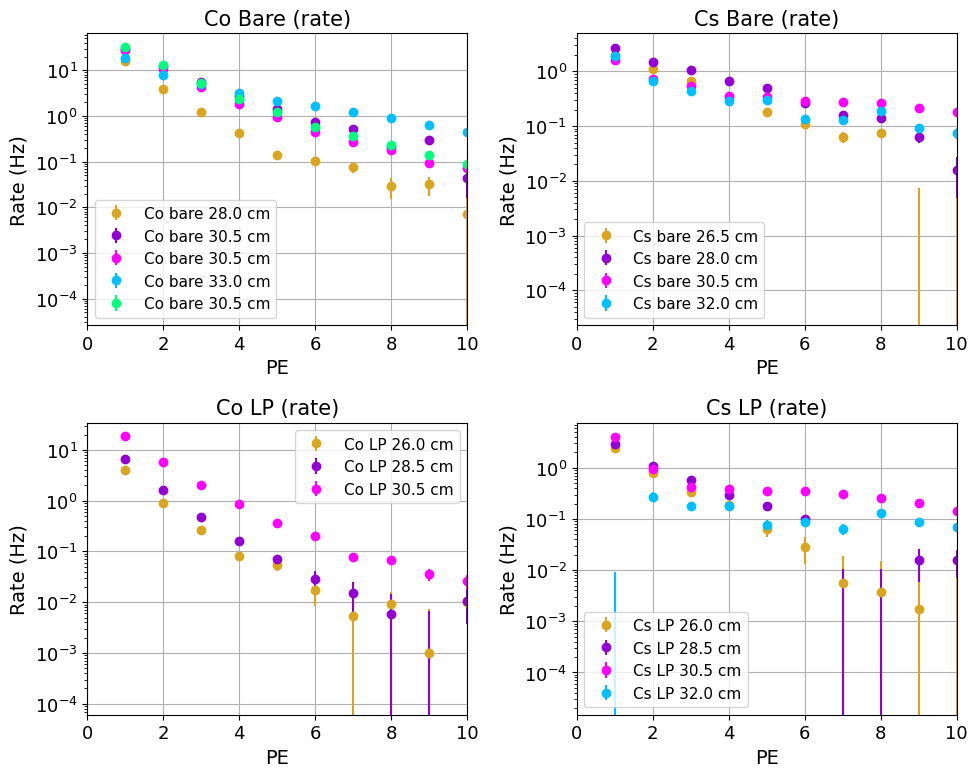

In [59]:
save_dir = os.path.join(COMP2PATH, "DataAnalysis", "saved_spectra2")

co_bare = PL.load_snap_list(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"))
cs_bare = PL.load_snap_list(os.path.join(save_dir, "rc_Cs_bare_source.snap.pkl"))
co_lp = PL.load_snap_list(os.path.join(save_dir, "rc_Co_LP_source.snap.pkl"))
cs_lp = PL.load_snap_list(os.path.join(save_dir, "rc_Cs_LP_source.snap.pkl"))

# Plot one example per category
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for lr in co_bare:
  lr.mpl_errorbar(axes[0,0], useCounts=False, label=f"Co bare {lr.height} cm", marker='o', linestyle='None')
axes[0,0].set_yscale('log'); axes[0,0].set_title("Co Bare (rate)"); axes[0,0].legend(); axes[0,0].grid(True)

for lr in cs_bare:
  lr.mpl_errorbar(axes[0,1], useCounts=False, label=f"Cs bare {lr.height} cm", marker='o', linestyle='None')
axes[0,1].set_yscale('log'); axes[0,1].set_title("Cs Bare (rate)"); axes[0,1].legend(); axes[0,1].grid(True)

for lr in co_lp:
  lr.mpl_errorbar(axes[1,0], useCounts=False, label=f"Co LP {lr.height} cm", marker='o', linestyle='None')
axes[1,0].set_yscale('log'); axes[1,0].set_title("Co LP (rate)"); axes[1,0].legend(); axes[1,0].grid(True)

for lr in cs_lp:
  lr.mpl_errorbar(axes[1,1], useCounts=False, label=f"Cs LP {lr.height} cm", marker='o', linestyle='None')
axes[1,1].set_yscale('log'); axes[1,1].set_title("Cs LP (rate)"); axes[1,1].legend(); axes[1,1].grid(True)

for rl in co_lp:
  print(np.sum(rl.counts_raw))

for ax in axes.flat:
  ax.set_xlabel("PE"); ax.set_ylabel("Rate (Hz)")
  ax.set_xlim(0, 10)

# fig.suptitle("Bacgkground-subtracted Spectra loaded from Pickle", fontsize=16)
plt.tight_layout(); plt.show()

In [60]:
import json5 as json 
import CompHelpers.MCdataSet as MCH
import CompHelpers.Comparator_generic as COMP
import CompHelpers.RealDataSet as RD

with open("compConfig.json") as f:
  compConfig = json.load(f)

hSkipList = compConfig["comparison"]["hSkipList"]
print("hSkipList:", hSkipList)

with open(os.path.join(COMP2PATH, "pyScripts", "analysis.json")) as f:
  anaConfig = json.load(f)["analysis"]

hSkipList: [-1, 0]


In [61]:
rds = RD.RealDataSet()

print(type(co_bare[0]))  # Should print the type of the first LiteRun object

rds.mCoLP = co_lp
rds.mCsLP = cs_lp
# rds.mCo = co_bare
# rds.mCs = cs_bare
# rds.mCoBare = co_bare
# rds.mCsBare = cs_bare

print(rds.mCoLP[0].mNEvents)

if rds.mCoLP[0].mHeight > 10:
  rds.ModifyHeights(hScale = compConfig["experiment"]["heightScale"])

## Rebin real data to match MC binning (from analysis.json)
rds.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"])
print(f"Real data rebinned to {anaConfig['nBins']} bins [{anaConfig['binLow']}-{anaConfig['binHigh']}]")

rds.print()

<class 'PickleLite.LiteRun'>
167817
Real data rebinned to 50 bins [0.5-50.5]

---- RealDataSet print() ----

    h         Nraw        Nsub     rate (Hz)    subRate (Hz)
Cs LP:
|    6.0 |  5.3e+04  |  5.25e+03  |   39.10 |   3.90
|    3.5 |  6.1e+04  |  7.73e+03  |   40.37 |   5.18
|    1.5 |  3.0e+04  |  5.39e+03  |   43.19 |   7.99
|    0.0 |  5.1e+04  |  2.99e+03  |   37.41 |   2.21

Co LP:
|    6.0 |  1.7e+05  |  2.21e+04  |   40.59 |   5.39
|    3.5 |  1.1e+05  |  2.24e+04  |   44.15 |   8.95
|    1.5 |  1.3e+05  |  5.79e+04  |   63.33 |  28.13


---
## load tools and MC spectra

In [62]:
# pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/gammaLP_apr17_rerunAgain_moreStats/"

# pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/gammaLP_ap17_swapped5cm/"

# pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/gammaMods/runB_shiny/"
# pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/batchOutput/gammaLP_refined_lowDensity_june11/"

# pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaLP_jun12_128K/"

pBatch3 = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaLP_june17_145K/"

# other = "gammaLP_Jan26_reduced"
mcDataPath = pBatch3
  
## making MC dataset
mc1 = MCH.MCdataSet(mcDataPath+"2/", buildOptions='all', skipRootHeights=[0.0])

mc1.doCAcorrection_BinomialMC(compConfig["mc_analysis"]["NCA"]) # makes var mNPE_corr
mc1.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"], variable='mNPE')
print("nbeam is:", mc1.mAllRuns[0].Nbeam)


print("--------\nlight yield is:", mc1.mAllRuns[0].mPhysPars.ly, " ph/keV")


['/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaLP_june17_145K/2/gammaCo57_base_LP_4d3V_h1d5.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaLP_june17_145K/2/gammaCo57_base_LP_4d3V_h3d5.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaLP_june17_145K/2/gammaCo57_base_LP_4d3V_h6d0.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaLP_june17_145K/2/gammaCs137_base_LP_4d3V_h6d0.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaLP_june17_145K/2/gammaCs137_base_LP_4d3V_h1d5.root', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaLP_june17_145K/2/gammaCs137_base_LP_4d3V_h3d5.root']
loaded in: /Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/gammaLP_june17_145K/2

<class 'Batch.helpers.G4_runClasses.FullMCRun'>
<class 'Batch.helpers.G4_runClasses.FullMCRun'>
<class 'Batch.helpers.G4_runClasses.FullMCRun'>


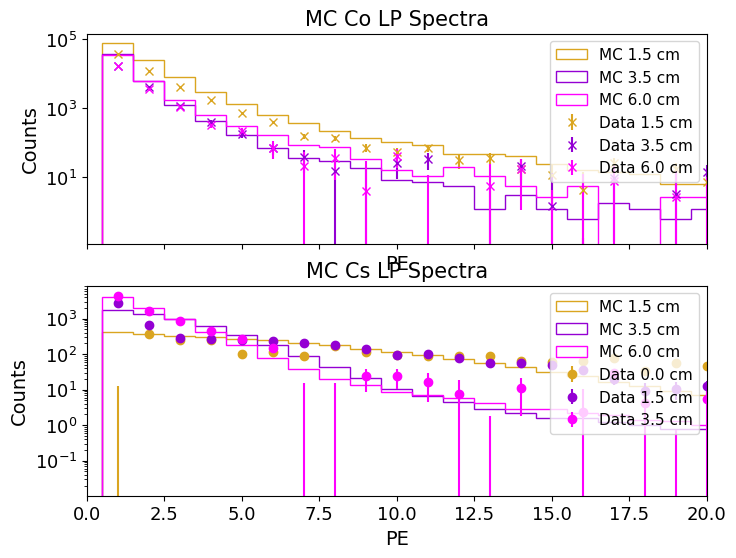

In [63]:
fig, (ax1, ax2) = plt.subplots(figsize=(8,6), nrows=2, sharex=True)
ax = ax1
for mc, dat in zip(mc1.mCoLPList, rds.mCoLP[::-1]):
  
  line = dat.mpl_errorbar(ax1, label=f"Data {32-dat.height} cm", marker="x", linestyle="None")
  
  dataArea = np.sum(dat.BkgCorrected_rawCounts)
  
  mcArea = np.sum(mc.mRaw_Counts)
  
  scale = 2*dataArea/mcArea
  
  # mc.mpl_errorbar(ax1, scale=scale, hshift = 0.1, label=f"MC {mc.mRunPars.gammaHeight} cm", marker="X", linestyle="None")
  mc.mpl_hist(ax1, scale = scale, hshift = 0, label=f"MC {mc.mRunPars.gammaHeight} cm", histtype='step', color = line.get_color())
  print(type(mc))

for mc, dat in zip(mc1.mCsLpList, rds.mCsLP[::-1]):
  # print(dat.height)
  # if 32-dat.height < 1:
  #   continue
  line = dat.mpl_errorbar(ax2, label=f"Data {32-dat.height} cm", marker="o", linestyle="None")
  
  dataArea = np.sum(dat.BkgCorrected_rawCounts)
  
  mcArea = np.sum(mc.mRaw_Counts)
  
  scale = dataArea/mcArea
  
  # mc.mpl_errorbar(ax2, scale=scale, hshift = 0.1, label=f"MC {mc.mRunPars.gammaHeight} cm", marker="x", linestyle="None")
  mc.mpl_hist(ax2, scale = scale, hshift = 0, label=f"MC {mc.mRunPars.gammaHeight} cm", histtype='step', color = line.get_color())

ax1.set_xlim(0, 20)
# ax1.vlines(range(1,11), ymin=1e-3, ymax=1e5, colors='gray', linestyles='dashed', alpha=0.5)
  
  
ax1.set_yscale('log')
ax.set_xlabel("PE")
ax.set_ylabel("Counts")
ax.set_title("MC Co LP Spectra")

ax2.set_yscale('log')
ax2.set_xlabel("PE")
ax2.set_ylabel("Counts")
ax2.set_title("MC Cs LP Spectra")

ax1.legend()
ax2.legend(loc='upper right')

plt.show()

---
### RC MC comparisons

To properly do comparison, must use the number of counts in the real data. so data corrected counts = raw counts - bkg rate x run time

In [64]:
comp1 = COMP.Comparator(rds)
comp1.hScale = compConfig["experiment"]["heightScale"]
comp1.mMCDataSet = mc1

# mc1.print()
# print("\n ---------------- \n")
# # rds.print(verbose=1, hScale = 0)
# print("\n ---------------- \n")
# comp1.SetBinRanges(1, 5, mode="value")
# res = mc1.findRunByHeight(3.5, key="colp")  # Test findRunByHeight
# print(mc1.gammaMap.keys())
# print(res)

print(comp1.ValidKeys)

def changeMCAllruns_height(mcHolder, h1, h2=6, stringCheck = "5cm"):
  eps = 0.1
  ## check name of pBath3
  if stringCheck in pBatch3:
    for run in mcHolder.mAllRuns:
      if np.abs(run.mRunPars.gammaHeight-h1) < eps:
        print("Found 5cm run, modifying height to 6cm for comparison")
        run.mRunPars.gammaHeight = h2
  return None

## this only executes if stringCheck is in the pBatch3 path, so it won't mess with other datasets
# changeMCAllruns_height(mc1, h1=5, h2=6, stringCheck="swapped5cm")


comp1.auto_map_by_common_heights(keys = ["colp", "cslp"], heightSkipList=compConfig["comparison"]["hSkipList"], verbose = 0)
# comp1.print(mcVerb = 1, dataVerb = 1)

# comp1.SetBinRanges(firstBin=2, lastBin = 8, mode="value", verbose=0);
# comp1.SetBinRanges_byCountLimit(firstBin=1, countLimit=5, option="data", verbose=1)

comp1.SetBinRanges_byCountLimit(firstBin=compConfig["comparison"]["compBin_low"], countLimit=compConfig["comparison"]["compCounts_high"], option=compConfig["comparison"]["countOption"], verbose=1)
# Override only the lower bin for the Cs 1.5 cm dataset
if 1.5 not in compConfig["comparison"]["hSkipList"]:
  comp1.SetBinRange_forRun(key="cslp", height=1.5, firstBin=compConfig["comparison"]["specialCsSkip_bin"], mode = "value")

# comp1.SetBinRanges_byCountLimit(firstBin=compConfig["comparison"]["compBin_low"], countLimit=compConfig["comparison"]["compCounts_high"], option=compConfig["comparison"]["countOption"], verbose=0)
print("analyzing keys:", comp1.keysUsed)

comp1.GuessOverallScaling()
gsc_co = comp1.statsCoLP.nuisGuess
gsc_cs = comp1.statsCsLP.nuisGuess

['csb', 'cob', 'cslp', 'colp']
Comparator.SetBinRanges_byCountLimit: 6 pairs, countLimit=10, option='both'
  h=6.0 Co57: data-limited, cutoff PE=9.00 (last included PE=8.00), nBins=7
  h=3.5 Co57: data-limited, cutoff PE=9.00 (last included PE=8.00), nBins=7
  h=1.5 Co57: data-limited, cutoff PE=16.00 (last included PE=15.00), nBins=14
  h=6.0 Cs137: data-limited, cutoff PE=7.00 (last included PE=6.00), nBins=5
  h=3.5 Cs137: data-limited, cutoff PE=7.00 (last included PE=6.00), nBins=5
  h=1.5 Cs137: data-limited, cutoff PE=18.00 (last included PE=17.00), nBins=16
  -> 6 pairs set; 0 with status != 0.
SetBinRange_forRun: patched key='cslp' h=1.5cm -> bins [2, 16] (x: 3.00 to 17.00), nBins=15
analyzing keys: ['colp', 'cslp']


Guess for cobalt scaling: 5998.583335573698
Guess for cesium scaling: 46.903605852785255


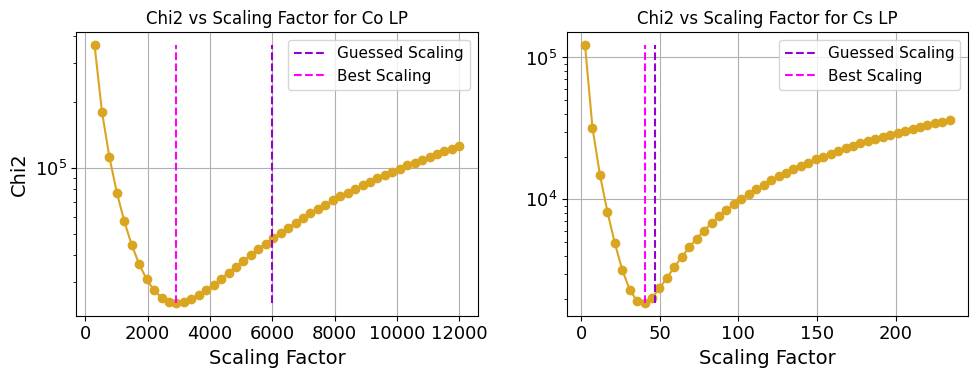

In [65]:
## manual scaling vs automatic minimization check

comp1.minimizeRateScaling(key="cslp", manual=True)
comp1.minimizeRateScaling(key="colp", manual=True)

print("Guess for cobalt scaling:", gsc_co)
xScaling_co = np.linspace(gsc_co*0.05, gsc_co*2, 50)
ychi2 = [comp1.CalcKeyChi2(key = "colp", scaling=scale) for scale in xScaling_co]
coScale = xScaling_co[np.argmin(ychi2)] ## testing

print("Guess for cesium scaling:", gsc_cs)
xScaling_cs = np.linspace(gsc_cs*0.05, gsc_cs*5, 50)
ychi2_cs = [comp1.CalcKeyChi2(key = "cslp", scaling=scale) for scale in xScaling_cs]
csScale = xScaling_cs[np.argmin(ychi2_cs)] ## testing

ms.ResetColorCycle()

fig, (axco, axcs) = plt.subplots(1, 2, figsize=(10, 4))
axco.plot(xScaling_co, ychi2, marker='o', color = ms.GetNextColor())
axco.vlines(gsc_co, ymin=min(ychi2), ymax=max(ychi2), colors=ms.GetNextColor(), linestyles='dashed', label='Guessed Scaling')
axco.vlines(coScale, ymin=min(ychi2), ymax=max(ychi2), colors=ms.GetNextColor(), linestyles='dashed', label='Best Scaling')

axco.set_title("Chi2 vs Scaling Factor for Co LP", fontsize = 12)

ms.ResetColorCycle()
axcs.plot(xScaling_cs, ychi2_cs, marker='o', color = ms.GetNextColor())
axcs.vlines(gsc_cs, ymin=min(ychi2_cs), ymax=max(ychi2_cs), colors=ms.GetNextColor(), linestyles='dashed', label='Guessed Scaling')
axcs.vlines(csScale, ymin=min(ychi2_cs), ymax=max(ychi2_cs), colors=ms.GetNextColor(), linestyles='dashed', label='Best Scaling')

axcs.set_title("Chi2 vs Scaling Factor for Cs LP", fontsize = 12)

for ax in [axco, axcs]:
  ax.set_xlabel("Scaling Factor")
  ax.set_ylabel("Chi2")
  ax.legend()
  ax.grid(True)

  ax.set_yscale('log')
  
axcs.set_ylabel(None)

plt.tight_layout()
plt.subplots_adjust(hspace=.0)

In [66]:
## singel scaling value (fixed ratios)
# bb = comp1.GetScaledGuess(keys=["colp", "cslp"], keyRatios=np.array([gsc_co, gsc_cs])/gsc_cs)
# cc = comp1.TotalChi2_singleScaling(scaling=np.average(bb), keys=["colp", "cslp"], keyRatios=np.array([gsc_co, gsc_cs])/gsc_cs)
# print(cc)

# singleScale, resSingle = comp1.minimizeRateScaling(statsOption="dualSource", key=["colp", "cslp"], kwargs={"keyRatios":np.array([actCo/actCs, 1.])}, manual=True)

In [67]:
print("first guess Co scaling:", gsc_co)
print("manually optimized Co scaling:", coScale)

lowScale, result = comp1.minimizeRateScaling(key="colp")
# print("lowScale:", lowScale) # same as below
print("minimizer optimized Co scaling:", comp1.statsCoLP.nuisScaling)
print("resulting chi2:", comp1.CalcKeyChi2(key = "colp", scaling=comp1.statsCoLP.nuisScaling))

print("---\nfirst guess Cs scaling:", gsc_cs)
print("manually optimized Cs scaling:", csScale)

lowScale_cs, result_cs = comp1.minimizeRateScaling(key="cslp")
# print("lowScale_cs:", lowScale_cs) # same as below
print("minimizer optimized Cs scaling:", comp1.statsCsLP.nuisScaling)
print("resulting chi2:", comp1.CalcKeyChi2(key = "cslp", scaling=comp1.statsCsLP.nuisScaling))

print("-----\ntotal red chi2 = ", comp1.GetTotalChi2(keys = ['colp', 'cslp']))

first guess Co scaling: 5998.583335573698
manually optimized Co scaling: 2925.8396269430887
minimizer optimized Co scaling: 2923.617860284983
resulting chi2: 24222.654597132154
---
first guess Cs scaling: 46.903605852785255
manually optimized Cs scaling: 40.25095155325755
minimizer optimized Cs scaling: 38.86795609635604
resulting chi2: 1853.9090952457493
-----
total red chi2 =  26076.563692377902


LiteRun 202204111600: plotting background-corrected counts
Cs h=6.0: bins [1-5] -> x=[2.0-6.0]
LiteRun 202204111454: plotting background-corrected counts
Cs h=3.5: bins [1-5] -> x=[2.0-6.0]
LiteRun 202204111423: plotting background-corrected counts
Cs h=1.5: bins [2-16] -> x=[3.0-17.0]
LiteRun 202204131513: plotting background-corrected counts
Co h=6.0: bins [1-7] -> x=[2.0-8.0]
LiteRun 202204131317: plotting background-corrected counts
Co h=3.5: bins [1-7] -> x=[2.0-8.0]
LiteRun 202204131122: plotting background-corrected counts
Co h=1.5: bins [1-14] -> x=[2.0-15.0]


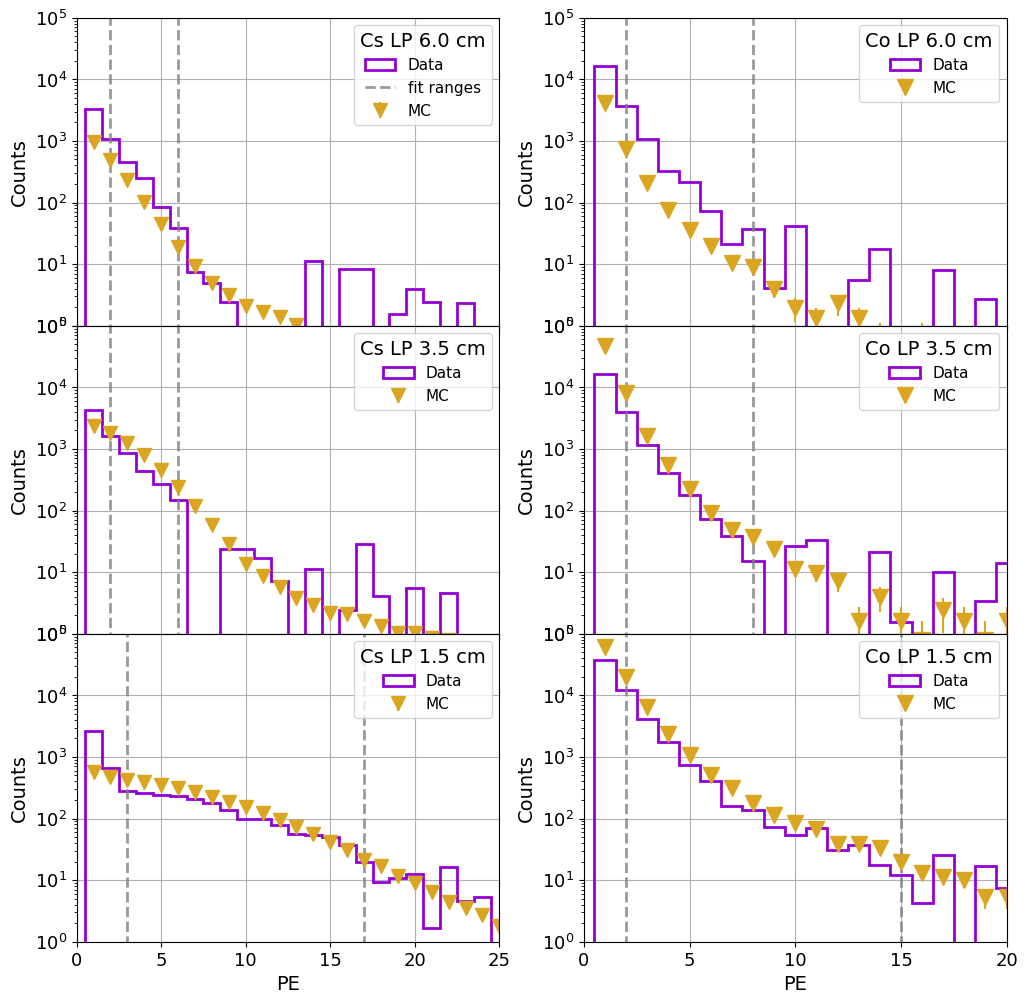

In [68]:
## can we plot the overlayed histograms at the best scaling?
if len(comp1.csLPpairs) >=3:
  nrows = 3
else:
  nrows = 2
fig, axes = plt.subplots(nrows, 2, figsize=(12, 4*nrows), sharex='col')
axA = axes[:, 0]  # First column (Cs)
axB = axes[:, 1]  # Second column (Co)

ms.ResetColorCycle()
color1 = ms.air.col
color2 = ms.lxe.col

## cs plots
for i, pair in enumerate(comp1.csLPpairs):
  ax = axA[i]
  # completeMCscale = csScale * pair.GetPrefac()
  # pair.mc.mpl_errorbar(ax, scale=completeMCscale, hshift = 0.0, label=f"MC {pair.mc.mRunPars.gammaHeight} cm", marker="X", linestyle="None")
  # singleScaleCs = singleScale * pair.GetPrefac() * 1
  
  # csScale = comp1._statsMap.get('cslp').nuisScaling * pair.GetPrefac()
  # print("this is cs nuis scaling:", comp1._statsMap.get('cslp').nuisScaling)
  csScale = lowScale_cs * pair.GetPrefac()
  # pair.rc.mpl_errorbar(ax, label=f"Data {pair.rc.height} cm", marker="o", linestyle="None")
  pair.rc.mpl_hist(ax, verbose = 1, label=f"Data", histtype='step', color = color2, linewidth = 2.)
  
  pair.mc.mpl_errorbar(ax, scale=csScale, hshift = 0.0, marker="v", linestyle="None", color = color1, markersize=10, label = "MC")
  
  ## vertical lines from StatsManager bin positions (specific to each pair)
  fx_fromBin = pair.rc.mBinX[pair.stats.firstBin]
  lx_fromBin = pair.rc.mBinX[pair.stats.lastBin]
  print(f"Cs h={pair.height:.1f}: bins [{pair.stats.firstBin}-{pair.stats.lastBin}] -> x=[{fx_fromBin:.1f}-{lx_fromBin:.1f}]")
  vline_label = "fit ranges" if i == 0 else "_nolegend_"
  ax.vlines([fx_fromBin, lx_fromBin], ymin=1e-3, ymax=1e5, linewidth = 2, colors='gray', linestyles='dashed', alpha=0.8, label=vline_label)
  
  legend = ax.legend(title=f"Cs LP {comp1.hScale-pair.rc.height:.1f} cm")
  legend.get_title().set_fontsize('medium')
  ax.set_ylabel("Counts")
  ax.set_yscale('log')
  if i < len(comp1.csLPpairs) - 1:
    ax.tick_params(labelbottom=False)
  else:
    ax.set_xlabel("PE")
  
for i, pair in enumerate(comp1.coLPpairs):
  ax = axB[i]
  # completeMCscale = coScale * pair.GetPrefac()
  # pair.mc.mpl_errorbar(ax, scale=completeMCscale, hshift = 0.0, label=f"MC {pair.mc.mRunPars.gammaHeight} cm", marker="x", linestyle="None")
  
  # singleScaleCo = singleScale * pair.GetPrefac() * actCo/actCs
  
  # pair.rc.mpl_errorbar(ax, label=f"Data {pair.rc.height} cm", marker="o", linestyle="None")
  pair.rc.mpl_hist(ax, verbose = 1, label=f"Data", histtype='step', color = color2, linewidth = 2.)
  
  coScale = comp1._statsMap.get('colp').nuisScaling * pair.GetPrefac()
  pair.mc.mpl_errorbar(ax, scale=coScale, hshift = 0.0, marker="v", linestyle="None", color = color1, markersize=12, label="MC")
  ## vertical lines from StatsManager bin positions (specific to each pair)
  fx_fromBin = pair.rc.mBinX[pair.stats.firstBin]
  lx_fromBin = pair.rc.mBinX[pair.stats.lastBin]
  print(f"Co h={pair.height:.1f}: bins [{pair.stats.firstBin}-{pair.stats.lastBin}] -> x=[{fx_fromBin:.1f}-{lx_fromBin:.1f}]")
  ax.vlines([fx_fromBin, lx_fromBin], ymin=1e-3, ymax=1e5, linewidth = 2, colors='gray', linestyles='dashed', alpha=0.8)
  
  legend = ax.legend(title=f"Co LP {comp1.hScale-pair.rc.height:.1f} cm")
  legend.get_title().set_fontsize('medium')
  ax.set_ylabel("Counts")
  ax.set_yscale('log')
  if i < len(comp1.coLPpairs) - 1:
    ax.tick_params(labelbottom=False)
  else:
    ax.set_xlabel("PE")

axs = np.append(axA, axB)
[ax.set_xlim(0, 25) for ax in axA];
[ax.set_xlim(0, 20) for ax in axB];

[ax.set_ylim(1, 1e5) for ax in axs];

[ax.grid() for ax in axs];
# plt.subplots_adjust(hspace=0.05)
plt.subplots_adjust(hspace=0.0)
# plt.tight_layout()
plt.show()


---
### Full dataset analysis

In [69]:
print(os.listdir(mcDataPath))

# check if comp1 exists before trying to delete
if 'comp1' in locals():
  print("deleted comp1")
  del comp1
if 'mc1' in locals():
  print("deleted mc1")
  del mc1

['0', '6', '1', '4', '3', '2', '5']
deleted comp1
deleted mc1


In [70]:
## making MC dataset - collect results silently, print summary at end
chis = []
lyList = []
scaling = []
guessScale = []
nbeamList = []
binInfoList = []  # Store bin range info including warnings

totalChis = []

dual = False
showSubrows = False  # Toggle to show/hide per-pair bin info

comp = COMP.Comparator(rds)
sortedListDir = sorted(os.listdir(mcDataPath))

# Suppress prints during loop - collect everything
import io
import contextlib

for folder in sortedListDir:
  
  if int(folder) == 8: ## only Co simulated in here
    continue
  
  # Capture any stray output from MCdataSet loading
  with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    mc = MCH.MCdataSet(mcDataPath+folder+"/", buildOptions='all', skipRootHeights=hSkipList, verbose=0)
    
    ly = mc.mAllRuns[0].mPhysPars.ly
    nbeam = mc.mAllRuns[0].Nbeam
    print("LY here:", ly)
    if ly < 1: # garbage
      continue
    
    ## add CA correction here
    mc.doCAcorrection_BinomialMC(compConfig["mc_analysis"]["NCA"]) # makes var mNPE_corr
    # mc.doCAcorrection_GeoMC(compConfig["mc_analysis"]["NCA"])
    
    # changeMCAllruns_height(mc, h1=5, h2=6, stringCheck="swapped5cm")
    
    mc.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"], variable='mNPE') #mNPE_corr
    mc.check_physPars_andDetPars(verbose=0)
  
  comp.hScale = compConfig["experiment"]["heightScale"]
  comp.mMCDataSet = mc
  
  comp.auto_map_by_common_heights(keys=["colp", "cslp"], heightSkipList=hSkipList, verbose=0)
  
  ## by low lim on byCountLimit goes by bins, so 1 excludes 1PE (first) bin
  ## SetBinRanges, mode = value goes by x value, so firstBin = 1 includes 1PE (0th bin) and above
  if compConfig["comparison"]["compFlag"] == "fixed":
    binInfo = comp.SetBinRanges(firstBin=compConfig["comparison"]["compPE_low"], lastBin=compConfig["comparison"]["compPE_high"], mode="value", verbose=1)
  elif compConfig["comparison"]["compFlag"] == "countLimit":
    binInfo = comp.SetBinRanges_byCountLimit(firstBin=compConfig["comparison"]["compBin_low"], countLimit=compConfig["comparison"]["compCounts_high"], option=compConfig["comparison"]["countOption"], verbose=2)
  else:
    raise ValueError(f"Invalid compFlag: {compConfig['comparison']['compFlag']}")
  
  # Per-run overrides applied after global bin-setting (any mode)
  if 1.5 not in compConfig["comparison"]["hSkipList"]:
    comp.SetBinRange_forRun(key="cslp", height=1.5, firstBin=2, mode="value", verbose=0)
  
  comp.GuessOverallScaling(keys=["colp", "cslp"])
  
  # print("guess after", comp._statsMap['cslp'].nuisGuess)
  # print("scaling before", comp._statsMap['cslp'].nuisScaling)
  
  scale1, fitRes = comp.minimizeRateScaling(key="cslp", manual=True, statsOption = "single")
  chi2_val = comp.CalcKeyChi2(key="cslp", scaling = scale1)
  # print("func return", scale1, fitRes)
  # print("scaling after", comp._statsMap['cslp'].nuisScaling)
  
  scale2, fitRes2 = comp.minimizeRateScaling(key="colp", manual=True, statsOption = "single")
  chi2_val2 = comp.CalcKeyChi2(key="colp", scaling = scale2)
  ## rerun with good values to reset internal stats trackers
  
  scaling.append([scale1, scale2])
  guessScale.append([comp.GetStats("cslp").nuisGuess, comp.GetStats("colp").nuisGuess])
  
  chis.append([chi2_val, chi2_val2])
  lyList.append(ly)
  nbeamList.append(nbeam)
  binInfoList.append(binInfo)
  
  totalChi2 = chi2_val + chi2_val2
  calculatedTotalChi2 = comp.GetTotalChi2(keys=["colp", "cslp"])
  summedTotalChi2 = chi2_val + chi2_val2
  
  totalNbins = comp.GetTotalNBins(keys=["colp", "cslp"])
  reducedChi2 = COMP.calc_reduced_chi2(totalChi2, totalNbins, nFitParams=2)  # 2 free params: one scaling per key
  totalChis.append([totalChi2, totalNbins, reducedChi2])

# Sort by LY
sorted_indices = np.argsort(lyList)
lyList = np.array(lyList)[sorted_indices]
chis = np.array(chis)[sorted_indices]
scaling = np.array(scaling)[sorted_indices]
guessScale = np.array(guessScale)[sorted_indices]
nbeamList = np.array(nbeamList)[sorted_indices]
binInfoList = [binInfoList[i] for i in sorted_indices]

totalChis = np.array(totalChis)[sorted_indices]
totalChiOnly = totalChis[:,0]
nBinsOnly = totalChis[:,1]
redChiOnly = totalChis[:,2]

### Printing ###
# Helper to format binInfo row
def fmt_binInfo(info):
  return f"{info.get('source','?')[:4]:<6} {info.get('height','?'):<6} {info.get('nBins','?'):<5} [{info.get('firstBinX',0):.0f}-{info.get('lastBinX',0):.0f}]"

# Print clean summary table
if showSubrows:
  print(f"{'Folder':<7} {'LY':<5} {'Scale':<10} {'Chi2':<10} | {'Src':<6} {'Ht':<6} {'nBin':<5} {'Range':<10}")
  print("="*75)
  for i, folder in enumerate(np.array(sortedListDir)[sorted_indices]):
    for j, info in enumerate(binInfoList[i]):
      if j == 0:
        print(f"{folder:<7} {lyList[i]:<5.1f} {scaling[i,0]:<10.3f} {chis[i,0]:<10.1f} | {fmt_binInfo(info)}")
      else:
        print(f"{'':<35} | {fmt_binInfo(info)}")
    print("-"*75)
else:
  print(f"{'Folder':<7} {'LY':<5} {'Scale(Cs)':<10} {'Scale(Co)':<10} {'Chi2(Cs)':<10} {'Chi2(Co)':<10}")
  print("="*70)
  for i, folder in enumerate(np.array(sortedListDir)[sorted_indices]):
    print(f"{folder:<7} {lyList[i]:<5.1f} {scaling[i,0]:<10.3f} {scaling[i,1]:<10.3f} {chis[i,0]:<10.1f} {chis[i,1]:<10.1f}")
  print("-"*70)

print(f"\nTotal folders: {len(lyList)}")

# Low-stat warnings summary
warnings = [(f, lyList[i], info) for i, f in enumerate(np.array(sortedListDir)[sorted_indices]) 
            for info in binInfoList[i] if info.get('status') == -1]
if warnings:
  print(f"\n⚠️ {len(warnings)} pairs with low MC stats (bins < countLimit in range)")

Comparator.SetBinRanges_byCountLimit: 6 pairs, countLimit=10, option='both'
  h=6.0 Co57: data+MC-limited, cutoff PE=9.00 (last included PE=8.00), nBins=7
  -> 6 pairs set; 0 with status != 0.
Comparator.SetBinRanges_byCountLimit: 6 pairs, countLimit=10, option='both'
  -> 6 pairs set; 0 with status != 0.
Comparator.SetBinRanges_byCountLimit: 6 pairs, countLimit=10, option='both'
  -> 6 pairs set; 0 with status != 0.
Comparator.SetBinRanges_byCountLimit: 6 pairs, countLimit=10, option='both'
  -> 6 pairs set; 0 with status != 0.
Comparator.SetBinRanges_byCountLimit: 6 pairs, countLimit=10, option='both'
  -> 6 pairs set; 0 with status != 0.
Comparator.SetBinRanges_byCountLimit: 6 pairs, countLimit=10, option='both'
  h=6.0 Co57: data+MC-limited, cutoff PE=9.00 (last included PE=8.00), nBins=7
  -> 6 pairs set; 0 with status != 0.
Comparator.SetBinRanges_byCountLimit: 6 pairs, countLimit=10, option='both'
  -> 6 pairs set; 0 with status != 0.
Folder  LY    Scale(Cs)  Scale(Co)  Chi2(Cs)

scaleCo: [4545.85722901 3779.06080664 3307.70854822 3088.16661193 2981.25081565
 2659.36158039 2182.58908089]
scaleCs: [50.33973691 45.05513587 42.32991615 41.21611062 39.41874001 38.08380805
 36.59143347]
--------

skipping heights [-1, 0]
comparing via method: countLimit
count limit: 1 10
min ly: 2.6 min chi2: 25189.850785723065
-------
fit success True
fit minimum at LY = 2.60 +/- 0.00
minimum chi2 = 25189.86 +/- 25.11
width error on chi2 0.004834056718316873
bestFit_scaleCo: 3197.9376
bestFit_scaleCs: 41.7730


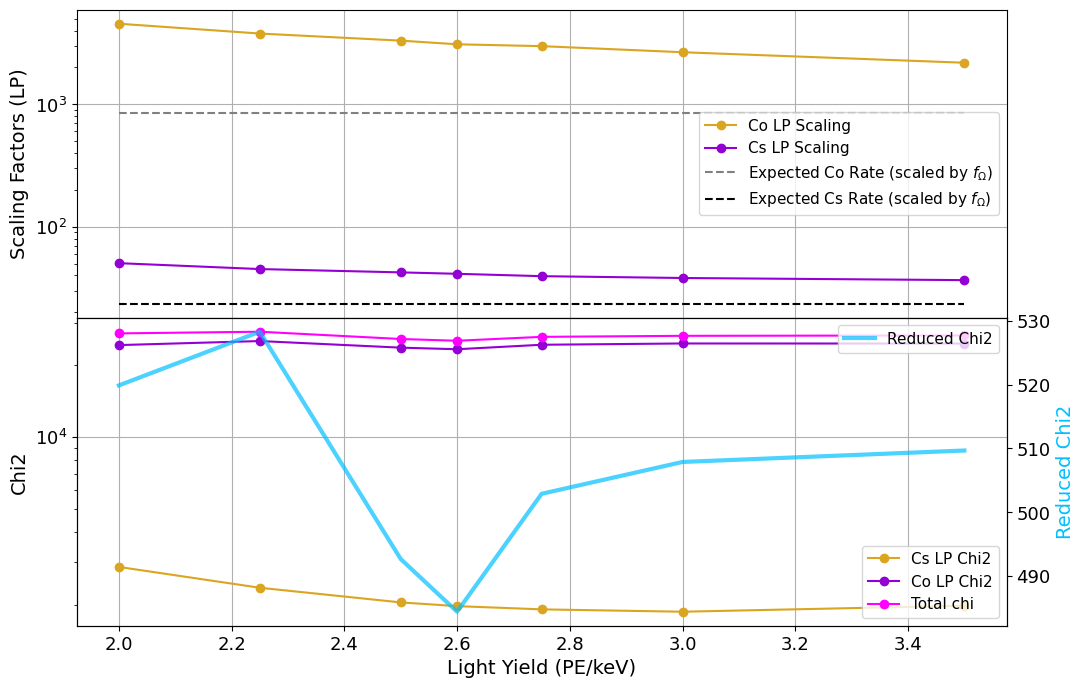

In [71]:
fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(12, 8), height_ratios=[1, 1], sharex=True)

import CompHelpers.Fitters as FTS

if not dual:
  scaleCs = np.array([scale[0] for scale in scaling])  # index 0 = cslp (scale1)
  scaleCo = np.array([scale[1] for scale in scaling])  # index 1 = colp (scale2)

  # ax1.plot(lyList, [g[0] for g in guessScale], marker='o', label='Co LP Guess Scaling')
  # ax2.plot(lyList, [g[1] for g in guessScale], marker='o', label='Cs LP Guess Scaling')

  ms.ResetColorCycle()
  ax1.plot(lyList, scaleCo, marker='o', label='Co LP Scaling', color = ms.GetNextColor())
  ax1.plot(lyList, scaleCs, marker='o', label='Cs LP Scaling', color = ms.GetNextColor())

  print("scaleCo:", scaleCo)
  print("scaleCs:", scaleCs)

  fsCo = fOmega * actCo
  fsCs = fOmega * actCs
  ax1.hlines(fsCo, xmin=min(lyList), xmax=max(lyList), colors='gray', linestyles='dashed', label=r'Expected Co Rate (scaled by $f_\Omega$)')
  ax1.hlines(fsCs, xmin=min(lyList), xmax=max(lyList), colors='black', linestyles='dashed', label=r'Expected Cs Rate (scaled by $f_\Omega$)')

  bb1 = [c[0]+c[1] for c in chis]
  bbCs = [c[0] for c in chis]
  bbCo = [c[1] for c in chis]
  
  ms.ResetColorCycle()
  ax3.plot(lyList, bbCs, marker='o', label='Cs LP Chi2', color = ms.GetNextColor())  # index 0 = cslp
  ax3.plot(lyList, bbCo, marker='o', label='Co LP Chi2', color = ms.GetNextColor())  # index 1 = colp
  ax3.plot(lyList, bb1, marker='o', label='Total chi', color = ms.GetNextColor())  # total chi2
  # ax3.plot(lyList, totalChiOnly/max(totalChiOnly), marker='o', alpha = 0.5, markersize = 5, label='Total Chi2', color = ms.GetNextColor())

  ax4 = ax3.twinx()
  # ms.ResetColorCycle()
  # ax4.plot(lyList, nBinsOnly, marker='o', label='Total Nbins')
  ax4.plot(lyList, redChiOnly, label='Reduced Chi2', color = ms.GetNextColor(), linewidth = 3, alpha = 0.7)
  # axx = ax4.twinx()
  # axx.plot(lyList, nBinsOnly, marker='o',  label='Total Nbins', color = ms.GetNextColor())
  # ax4.plot(lyList, nBinsOnly, marker='o', label='Total Nbins')

elif dual:
  ax3.plot(lyList, chis, marker='o', label='Total chi2 (single scaling)')

# pValues = COMP.calc_pvalue(chi2=totalChiOnly, nBins=nBinsOnly, nFitParams=2)
# ax5.plot(lyList, pValues, marker='o', label='p-value (total chi2)')
# print(max(pValues))

print("--------\n\nskipping heights", hSkipList)
print("comparing via method:", compConfig["comparison"]["compFlag"])

if compConfig["comparison"]["compFlag"] == "countLimit":
  print("count limit:", compConfig["comparison"]["compBin_low"], compConfig["comparison"]["compCounts_high"])
elif compConfig["comparison"]["compFlag"] == "fixed":
  print("PE range:", compConfig["comparison"]["compPE_low"], "-", compConfig["comparison"]["compPE_high"])

#### Fitting ####
if 1:
  minLYvalue = lyList[np.argmin(totalChiOnly)]
  minLYindex = np.argmin(totalChiOnly)
  print("min ly:", minLYvalue, "min chi2:", min(totalChiOnly))

  chiToPass = totalChiOnly
  # chiToPass = redChiOnly  # try reduced chi2 for fit instead of total chi2 to avoid overweighting high-ly points with many bins
  if minLYvalue <= 2:
    chiToPass = redChiOnly

  res, outstr = FTS.fit_quadratic_minimum(lyList[minLYindex-1:minLYindex+2], chiToPass[minLYindex-1:minLYindex+2])
  print("-------\nfit success", res['success'])
  # print("fit minimum at LY =", res['x0'], "+/-", res['x0_err'])
  print(f"fit minimum at LY = {res['x0']:.2f} +/- {res['x0_err']:.2f}")
  print(f"minimum chi2 = {res['y0']:.2f} +/- {res['y0_err']:.2f}")

  print("width error on chi2", 1/np.sqrt(res['a']))  # rough estimate of LY uncertainty from fit curvature

  ## plot the fit
  minXfromFit = res['x0']
  x_fit = np.linspace(lyList[minLYindex-1], lyList[minLYindex+1], 100)
  y_fit = FTS.quadratic(x_fit, res['a'], res['x0'], res['y0'])

  # if minLYvalue > 2:
  #   ax3.plot(x_fit, y_fit, label='Quadratic Fit to Cs LP Chi2', color='gray', linestyle='dashed')
  # else:
  #   ax4.plot(x_fit, y_fit, label='Quadratic Fit to Cs LP Chi2', color='gray', linestyle='dashed')

  ## compute the 'true' rate scaling parameter at the fit minimum and compare to expected
  # really we will just take the average of the two neighboring points
  diffs = np.abs(lyList - minXfromFit)
  closest_two = np.argsort(diffs)[:2]
  bestFit_scaleCo = np.mean(scaleCo[closest_two])
  bestFit_scaleCs = np.mean(scaleCs[closest_two])
  print(f"bestFit_scaleCo: {bestFit_scaleCo:.4f}")
  print(f"bestFit_scaleCs: {bestFit_scaleCs:.4f}")

ax1.set_ylabel("Scaling Factors (LP)")
ax1.legend()
ax1.set_yscale('log')

ax1.grid(True)

ax3.set_ylabel("Chi2")
ax3.set_xlabel("Light Yield (PE/keV)")
ax3.legend(loc = 'lower right')
ax3.grid(True)

ax4.set_xlabel("Light Yield (PE/keV)")
ax4.legend()
ax4.set_ylabel("Reduced Chi2", color = ms.cf4.col)

ax3.set_yscale("log")
# ax3.set_xlim(2.3, ax3.get_xlim()[1])
# ax4.set_yscale('log')

# plt.tight_layout()
plt.subplots_adjust(hspace=0.)


In [76]:
## Systematic scan: firstBin x heightSkip combinations
# Uses SetBinRanges_byCountLimit for all cases
# Fits quadratic to total chi2 vs LY for each case

import CompHelpers.Fitters as FTS

firstBin_list = [1, 2]  # 0-based bin indices: 1 -> 2PE, 2 -> 3PE
# firstBin_list = [1, 2]  # 0-based bin indices: 1 -> 2PE, 2 -> 3PE

hSkip_configs = {
    "all":       [0.0],
    "skip 6cm":  [0.0, 6.0],
    "skip 1.5cm":[0.0, 1.5]
}

countLim = compConfig["comparison"]["compCounts_high"]

scan_results = {}
i = 0

for fb in firstBin_list:
  for hLabel, hSkip in hSkip_configs.items():
    tag = f"firstBin={fb}, {hLabel}"

    lyArr = []
    totalChi2Arr = []
    totalNbinsArr = []
    scaleCoArr = []
    scaleCsArr = []

    compS = COMP.Comparator(rds)
    i += 1

    for folder in sorted(os.listdir(mcDataPath)):
      with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        mcS = MCH.MCdataSet(mcDataPath+folder+"/", buildOptions='all', skipRootHeights=hSkip, verbose=0)
        ly = mcS.mAllRuns[0].mPhysPars.ly
        if ly < 1:
          continue
        mcS.doCAcorrection_BinomialMC(compConfig["mc_analysis"]["NCA"])
        mcS.setup_forComparison(anaConfig["nBins"], anaConfig["binLow"], anaConfig["binHigh"], variable='mNPE')
        mcS.check_physPars_andDetPars(verbose=0)
        # changeMCAllruns_height(mcS, h1=5, h2=6, stringCheck="swapped5cm")

      compS.hScale = compConfig["experiment"]["heightScale"]
      compS.mMCDataSet = mcS
      compS.auto_map_by_common_heights(keys=["colp", "cslp"], heightSkipList=hSkip, verbose=0)
      compS.SetBinRanges_byCountLimit(firstBin=fb, countLimit=countLim, option=compConfig["comparison"]["countOption"], verbose=1)
      # compS.SetBinRanges(firstBin=fb+1, lastBin=compConfig["comparison"]["compPE_high"], mode="value", verbose=0)
      
      # Override only the lower bin for the Cs 1.5 cm dataset
      if 1.5 not in hSkip:
        compS.SetBinRange_forRun(key="cslp", height=1.5, firstBin=compConfig["comparison"]["specialCsSkip_bin"], mode = "value")
      
      compS.GuessOverallScaling(keys=["colp", "cslp"])

      s1, _ = compS.minimizeRateScaling(key="cslp", manual=True, statsOption="single")
      chi2_cs = compS.CalcKeyChi2(key="cslp", scaling=s1)

      s2, _ = compS.minimizeRateScaling(key="colp", manual=True, statsOption="single")
      chi2_co = compS.CalcKeyChi2(key="colp", scaling=s2)

      lyArr.append(ly)
      totalChi2Arr.append(chi2_cs + chi2_co)
      totalNbinsArr.append(compS.GetTotalNBins(keys=["colp", "cslp"]))
      scaleCoArr.append(s2)
      scaleCsArr.append(s1)

    # Sort by LY
    idx = np.argsort(lyArr)
    lyArr = np.array(lyArr)[idx]
    totalChi2Arr = np.array(totalChi2Arr)[idx]
    totalNbinsArr = np.array(totalNbinsArr)[idx]
    reducedChi2Arr = totalChi2Arr/(totalNbinsArr - 2)
    scaleCoArr = np.array(scaleCoArr)[idx]
    scaleCsArr = np.array(scaleCsArr)[idx]

    # Fit quadratic
    print("--\nfitting case:", tag)

    # Check total chi2 min
    minLYvalue = lyArr[np.argmin(totalChi2Arr)]  # if total chi2 min is at edge, skip fit
    minLYindex = np.argmin(totalChi2Arr)
    minLY_reduced = lyArr[np.argmin(reducedChi2Arr)]

    res = None
    resReduced = None
    bestFit_scaleCo = None
    bestFit_scaleCs = None
    print("min ly at:", lyArr[minLYindex])
    if minLYvalue != min(lyArr) and minLYvalue != max(lyArr):
      res, outstr = FTS.fit_quadratic_minimum(lyArr[minLYindex-1:minLYindex+2], totalChi2Arr[minLYindex-1:minLYindex+2])
      print(outstr)
      # print("counter:", i)

      # find the two closest scaleCo/scaleCs values to the fit minimum x
      diffs = np.abs(lyArr - res['x0'])
      closest_two = np.argsort(diffs)[:2]
      bestFit_scaleCo = np.mean(scaleCoArr[closest_two])
      bestFit_scaleCs = np.mean(scaleCsArr[closest_two])

    # if minLY_reduced != 1 and minLY_reduced != 7:
    #   resReduced = FTS.fit_quadratic_minimum(lyArr[minLYindex-1:minLYindex+2], reducedChi2Arr[minLYindex-1:minLYindex+2])
    resReduced = None

    scan_results[tag] = {
        'ly': lyArr,
        'totalChi2': totalChi2Arr,
        'reducedChi2': reducedChi2Arr,
        'totalNbins': totalNbinsArr,
        'fit': res,
        'fitReduced': resReduced,
        'bestFit_scaleCo': bestFit_scaleCo,
        'bestFit_scaleCs': bestFit_scaleCs,
    }


Comparator.SetBinRanges_byCountLimit: 6 pairs, countLimit=10, option='both'
  h=6.0 Co57: data+MC-limited, cutoff PE=9.00 (last included PE=8.00), nBins=7
  h=3.5 Co57: data-limited, cutoff PE=9.00 (last included PE=8.00), nBins=7
  h=1.5 Co57: data-limited, cutoff PE=16.00 (last included PE=15.00), nBins=14
  h=6.0 Cs137: data-limited, cutoff PE=7.00 (last included PE=6.00), nBins=5
  h=3.5 Cs137: data-limited, cutoff PE=7.00 (last included PE=6.00), nBins=5
  h=1.5 Cs137: data-limited, cutoff PE=18.00 (last included PE=17.00), nBins=16
  -> 6 pairs set; 0 with status != 0.
SetBinRange_forRun: patched key='cslp' h=1.5cm -> bins [2, 16] (x: 3.00 to 17.00), nBins=15
Comparator.SetBinRanges_byCountLimit: 6 pairs, countLimit=10, option='both'
  h=6.0 Co57: data-limited, cutoff PE=9.00 (last included PE=8.00), nBins=7
  h=3.5 Co57: data-limited, cutoff PE=9.00 (last included PE=8.00), nBins=7
  h=1.5 Co57: data-limited, cutoff PE=16.00 (last included PE=15.00), nBins=14
  h=6.0 Cs137: data

In [77]:
print("\n\n=== Systematic Scan Summary ===")

print(f"\n--- Total χ² fits ---")
print(f"{'Case':<30} {'LY_min':>8} {'± LY':>8} {'Δχ²=1':>7} {'χ²_min':>8} {'nBins*':>7} {'redχ²':>7} {'scaleCo':>10} {'scaleCs':>10} {'fit ok':>6}")
print("=" * 110)
for tag, r in scan_results.items():
    fit = r['fit']
    bfCo = r.get('bestFit_scaleCo')
    bfCs = r.get('bestFit_scaleCs')
    if fit is not None:
      nBins_at_min    = r['totalNbins'][np.argmin(np.abs(r['ly'] - fit['x0']))]
      redChi2_at_min  = fit['y0'] / (nBins_at_min - 2)
      dly             = 1.0 / np.sqrt(fit['a']) if fit.get('a', 0) > 0 else float('nan')
      scaleCo_str     = f"{bfCo:.4f}" if bfCo is not None else "  N/A  "
      scaleCs_str     = f"{bfCs:.4f}" if bfCs is not None else "  N/A  "
      print(f"{tag:<30} {fit['x0']:>8.2f} {fit['x0_err']:>8.2f} {dly:>7.2f} {fit['y0']:>8.1f} {nBins_at_min:>7.0f} {redChi2_at_min:>7.2f} {scaleCo_str:>10} {scaleCs_str:>10} {'✓' if fit['success'] else '✗':>6}")
    else:
      print(f"{tag:<30} {'(min at edge, skipped)':>70}")

print(f"\n* nBins at the LY closest to the fitted minimum")
print(f"  Δχ²=1 : half-width of quadratic at χ²_min + 1  (1σ interval on LY)")

print("expected scaleCo", fOmega * actCo)
print("expected scaleCs", fOmega * actCs)



=== Systematic Scan Summary ===

--- Total χ² fits ---
Case                             LY_min     ± LY   Δχ²=1   χ²_min  nBins*   redχ²    scaleCo    scaleCs fit ok
firstBin=1, all                    2.60     0.00    0.00  25157.6      53  493.29  3197.9376    40.8758      ✓
firstBin=1, skip 6cm               2.93     0.00    0.04    538.8      41   13.81  1694.4501    28.4922      ✓
firstBin=1, skip 1.5cm             2.49     0.00    0.01  16248.8      24  738.58  5152.1418    45.5187      ✓
firstBin=2, all                    2.63     0.00    0.01   7666.4      48  166.66  3174.1094    34.3834      ✓
firstBin=2, skip 6cm               2.88     0.01    0.06    165.3      38    4.59  1849.7204    26.0731      ✓
firstBin=2, skip 1.5cm             2.66     0.00    0.01   4461.8      20  247.88  5573.2587    38.0797      ✓

* nBins at the LY closest to the fitted minimum
  Δχ²=1 : half-width of quadratic at χ²_min + 1  (1σ interval on LY)
expected scaleCo 846.4371515011024
expected scal

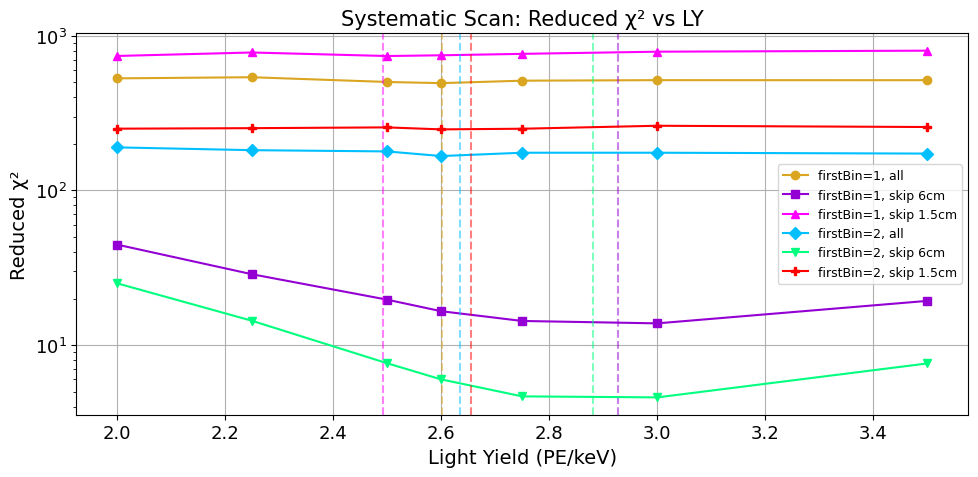

In [78]:
## Plot reduced chi2 vs LY for each systematic case
markers = ['o', 's', '^', 'D', 'v', 'P', '*', 'X', 'h', '+']
fig, ax = plt.subplots(figsize=(10, 5))

for i, (tag, r) in enumerate(scan_results.items()):
    fit = r['fit']
    marker = markers[i % len(markers)]
    line, = ax.plot(r['ly'], r['reducedChi2'], marker=marker, label=tag)
    if fit is not None and fit['success']:
        ax.axvline(fit['x0'], color=line.get_color(), linestyle='dashed', alpha=0.5)

ax.set_xlabel("Light Yield (PE/keV)")
ax.set_ylabel("Reduced χ²")
ax.set_title("Systematic Scan: Reduced χ² vs LY")
ax.legend(fontsize=9)
ax.grid(True)
ax.set_yscale('log')
plt.tight_layout()
plt.show()


In [79]:
## compute weighted average LY + uncertainty from scan fits
valid_fits = [r['fit'] for r in scan_results.values() if r['fit'] is not None and r['fit']['success']]

if valid_fits:
    x = np.array([fit['x0'] for fit in valid_fits], dtype=float)
    chi2min = np.array([fit['y0'] for fit in valid_fits], dtype=float)

    # Keep your original weighting choice: w = 1/chi2_min
    w = 1.0 / np.clip(chi2min, 1e-12, None)
    wsum = np.sum(w)
    weighted_avg_ly = np.sum(w * x) / wsum

    # Uncertainty estimate 1: weighted spread of fitted minima
    weighted_var = np.sum(w * (x - weighted_avg_ly) ** 2) / wsum
    weighted_std = np.sqrt(weighted_var)

    # Effective sample size for weighted data
    neff = (wsum ** 2) / np.sum(w ** 2)
    weighted_sem = weighted_std / np.sqrt(neff) if neff > 1 else np.nan

    print(f"\nWeighted average (1/chi2) LY from valid fits: {weighted_avg_ly:.2f} PE/keV")
    print(f"Weighted spread (w-std): ±{weighted_std:.2f} PE/keV")
    if np.isfinite(weighted_sem):
        print(f"Error on weighted mean (w-SEM): ±{weighted_sem:.2f} PE/keV (N_eff={neff:.2f})")
    else:
        print("Error on weighted mean (w-SEM): undefined (need >1 effective fit)")

    # Optional uncertainty estimate 2: weighted by 1/fit uncertainty if available
    x0_err = np.array([fit.get('x0_err', np.nan) for fit in valid_fits], dtype=float)
    good_err = np.isfinite(x0_err) & (x0_err > 0)
    if np.any(good_err):
        w_err = 1.0 / (x0_err[good_err] ** 2)
        x_err = x[good_err]
        ly_ivw = np.sum(w_err * x_err) / np.sum(w_err)
        ly_ivw_err = np.sqrt(1.0 / np.sum(w_err))
        print(f"Inverse fit error LY (using x0_err): {ly_ivw:.2f} ± {ly_ivw_err:.2f} PE/keV")
else:
    print("\nNo valid fits to compute weighted average LY")


Weighted average (1/chi2) LY from valid fits: 2.88 PE/keV
Weighted spread (w-std): ±0.07 PE/keV
Error on weighted mean (w-SEM): ±0.05 PE/keV (N_eff=1.74)
Inverse fit error LY (using x0_err): 2.61 ± 0.00 PE/keV
